# Hands-On Practice: Sensitivity Analysis
In this notebook, we simulate a simple business model for a new product launch. We will run both **One-Way Sensitivity Analysis** (Tornado Chart) to find out which variable matters most, and **Two-Way Sensitivity Analysis** (Heatmap) to find our safe operating zones.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-darkgrid')

### 1. The Base Case
First, we define our "Best Guess" for the business model. This is the baseline everything else is compared against.

**Profit = (Selling Price - Variable Cost) * Units Sold - Fixed Costs**

In [2]:
# The Base Model Inputs
base_price = 50.0
base_var_cost = 30.0
base_units = 10000
base_fixed_cost = 100000

def calc_profit(price, var_cost, units, fixed_cost):
    return (price - var_cost) * units - fixed_cost

base_profit = calc_profit(base_price, base_var_cost, base_units, base_fixed_cost)
print(f"Base Case Profit: ${base_profit:,.2f}")

Base Case Profit: $100,000.00


### 2. One-Way Sensitivity Analysis (The Tornado Chart)
What happens if our assumptions are off by +/- 20%? We change ONE variable at a time, keeping everything else at the Base Case, to see which variable causes the biggest swing in profit.

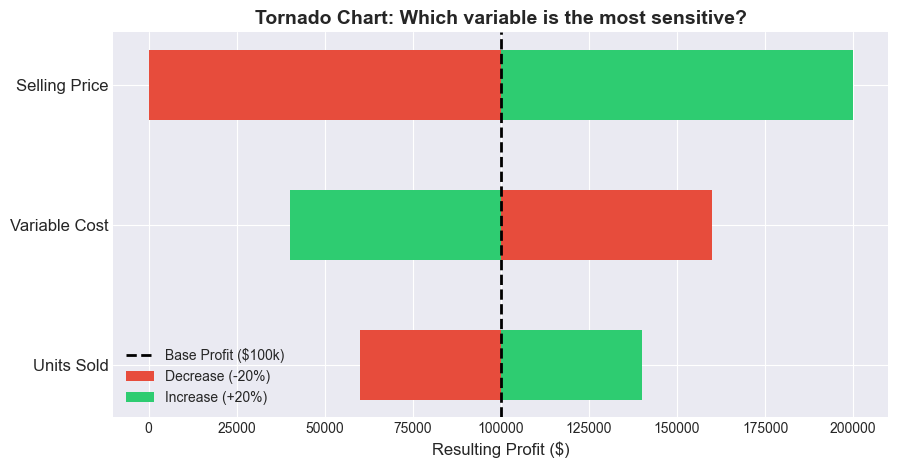

CONCLUSION: Selling Price is by far the most 'sensitive' variable. If we get the price wrong by 20%, we go completely bankrupt. Management must focus heavily on pricing strategy.


In [3]:
# Define the +/- percentage swing
swing = 0.20  # 20%

# Calculate swings for each variable
scenarios = {
    'Selling Price': {
        'Low (-20%)': calc_profit(base_price * (1-swing), base_var_cost, base_units, base_fixed_cost),
        'High (+20%)': calc_profit(base_price * (1+swing), base_var_cost, base_units, base_fixed_cost)
    },
    'Variable Cost': {
        'Low (-20%)': calc_profit(base_price, base_var_cost * (1-swing), base_units, base_fixed_cost),
        'High (+20%)': calc_profit(base_price, base_var_cost * (1+swing), base_units, base_fixed_cost)
    },
    'Units Sold': {
        'Low (-20%)': calc_profit(base_price, base_var_cost, base_units * (1-swing), base_fixed_cost),
        'High (+20%)': calc_profit(base_price, base_var_cost, base_units * (1+swing), base_fixed_cost)
    }
}

# Extract data for plotting
labels = list(scenarios.keys())
lows = [scenarios[k]['Low (-20%)'] for k in labels]
highs = [scenarios[k]['High (+20%)'] for k in labels]

# Calculate the total swing (High - Low) and sort variables by impact
impacts = [abs(h - l) for h, l in zip(highs, lows)]
sorted_indices = np.argsort(impacts)
labels = [labels[i] for i in sorted_indices]
lows = [lows[i] for i in sorted_indices]
highs = [highs[i] for i in sorted_indices]

# Plot the Tornado Chart
fig, ax = plt.subplots(figsize=(10, 5))
y_pos = np.arange(len(labels))

ax.barh(y_pos, [l - base_profit for l in lows], left=base_profit, height=0.5, color='#e74c3c', label='Decrease (-20%)')
ax.barh(y_pos, [h - base_profit for h in highs], left=base_profit, height=0.5, color='#2ecc71', label='Increase (+20%)')

ax.axvline(base_profit, color='black', linestyle='--', linewidth=2, label='Base Profit ($100k)')
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=12)
ax.set_xlabel('Resulting Profit ($)', fontsize=12)
ax.set_title('Tornado Chart: Which variable is the most sensitive?', fontsize=14, fontweight='bold')
ax.legend()
plt.show()

print("CONCLUSION: Selling Price is by far the most 'sensitive' variable. If we get the price wrong by 20%, we go completely bankrupt. Management must focus heavily on pricing strategy.")

### 3. Two-Way Sensitivity Analysis (The Heatmap)
We know Price and Units Sold are the biggest drivers. What happens if we move BOTH of them at the same time? 
We will build a grid testing Prices from $40 to $60, and Units Sold from 5,000 to 15,000.

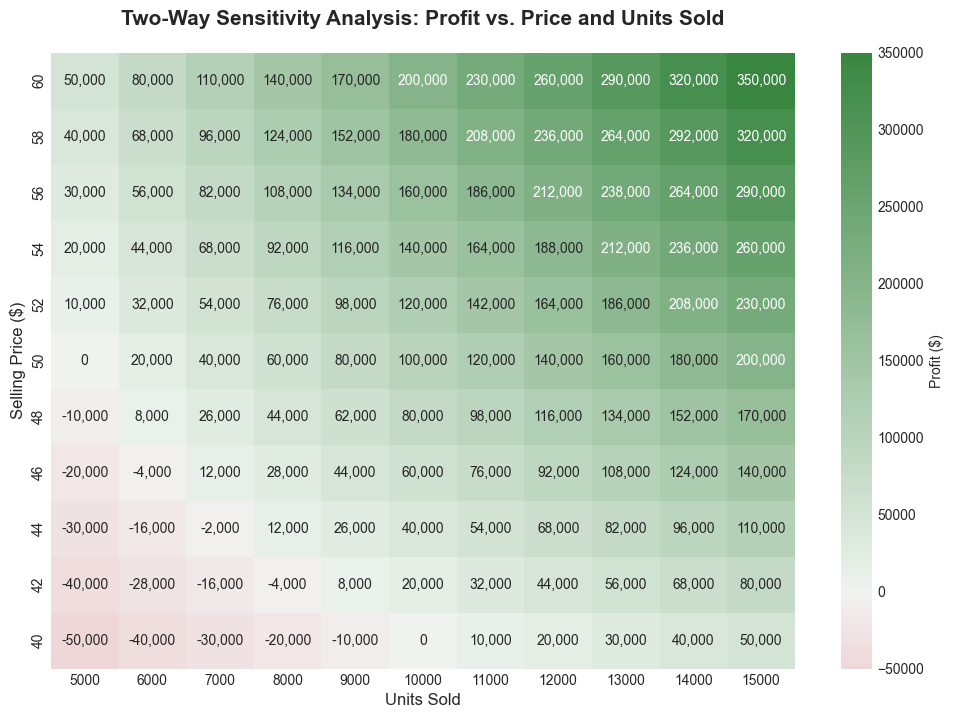

CONCLUSION: The Heatmap clearly shows the 'Safe Zone' (Green cells) and the 'Danger Zone' (Red cells). Even if we sell 15,000 units (Best Case), if our price drops below $40, we will still lose money!


In [4]:
prices = np.arange(40, 62, 2)     # [40, 42, 44... 60]
units = np.arange(5000, 16000, 1000) # [5000, 6000... 15000]

# Create an empty matrix to hold the profits
profit_matrix = np.zeros((len(prices), len(units)))

# Fill the matrix
for i, p in enumerate(prices):
    for j, u in enumerate(units):
        profit_matrix[i, j] = calc_profit(p, base_var_cost, u, base_fixed_cost)

# Convert to DataFrame for easy Seaborn plotting
df_heatmap = pd.DataFrame(profit_matrix, index=prices, columns=units)

# Plot the Heatmap
plt.figure(figsize=(12, 8))
# Custom colormap: Red for negative, White for near zero, Green for positive
cmap = sns.diverging_palette(10, 130, as_cmap=True)

sns.heatmap(df_heatmap, cmap=cmap, center=0, annot=True, fmt=",.0f", cbar_kws={'label': 'Profit ($)'})
plt.title('Two-Way Sensitivity Analysis: Profit vs. Price and Units Sold', fontsize=15, fontweight='bold', pad=20)
plt.ylabel('Selling Price ($)', fontsize=12)
plt.xlabel('Units Sold', fontsize=12)

plt.gca().invert_yaxis() # Put lowest price at bottom
plt.show()

print("CONCLUSION: The Heatmap clearly shows the 'Safe Zone' (Green cells) and the 'Danger Zone' (Red cells). Even if we sell 15,000 units (Best Case), if our price drops below $40, we will still lose money!")